# A deformable-mirror stroke budget with `budgie.tree`

This notebook builds, checks and renders a DM stroke budget from a few lines of YAML.
There is no budget class: the terms, the per-group combine rules and the roll-up chain are data,
and `budgie.tree` does the math and the drawing. It is self-contained; the only dependency is
`budgie` itself (install cell below). LaTeX figures need `pdflatex` with `forest` and `pdftoppm`;
without them the LaTeX source is printed instead.

Units are peak-to-valley **surface** stroke in nm (surface = wavefront / 2 at near-normal incidence).

In [1]:
# Install budgie if it is not already available (uncomment the branch you want).
try:
    import budgie.tree  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/douglase/budgie.git@develop"], check=True)

In [2]:
from pathlib import Path
import shutil
import subprocess
import tempfile

import yaml
from IPython.display import Image

from budgie.tree import BudgetTreeError, build_tree, render_ascii, render_tikz

## 1. The budget is data

Each term has an `Allocation` (the stroke specified for it), a `CBE` (current best estimate) and a `Type`
(its group). `category_combine_ops` says how each group combines its terms: `sum` when demands can stack
on the same actuator, `rss` when they are independent. `post_processing_chain` rolls the groups up, and
`budget.available` is the stroke the DM can deliver.

In [3]:
BUDGET = """
budget:
  name: Example DM stroke budget
  units: nm
  available: 1400          # stroke the DM can deliver

config:
  category_combine_ops:    # per-group rule: sum (stacking) or rss (independent)
    static: sum
    dynamic: sum
    image_plane_wfc: sum
  post_processing_chain:
    - {op: sum, label: Total stroke used}

terms:
  - {Name: telescope,           Type: static,          Allocation: 85,  CBE: 80}
  - {Name: instrument,          Type: static,          Allocation: 15,  CBE: 12}
  - {Name: dm_flat_map,         Type: static,          Allocation: 300, CBE: 280}
  # 28 nm RMS wavefront x 5 (PV/RMS) / 2 = 70 nm surface PV would be entered as Allocation: 70
  - {Name: telescope_low_order, Type: dynamic,         Allocation: 50,  CBE: 45}
  - {Name: dark_hole,           Type: image_plane_wfc, Allocation: 50,  CBE: 40}
"""
data = yaml.safe_load(BUDGET)

## 2. Build the tree

`build_tree` turns the flat term list into leaves, one subtotal node per `Type`, and the roll-up chain.
Every non-leaf node carries both the combined CBE (`value`) and the combined allocation.

In [4]:
root = build_tree(data["terms"], config=data["config"])
print(render_ascii(root))

Total stroke used ... 4.6e+02 (5.0e+02 alloc)
├── $\sum$ static (subtotal) ... 3.7e+02 (4.0e+02 alloc)
│   ├── $\sum$ telescope ... 8.0e+01 (8.5e+01 alloc)
│   ├── $\sum$ instrument ... 1.2e+01 (1.5e+01 alloc)
│   └── $\sum$ dm_flat_map ... 2.8e+02 (3.0e+02 alloc)
├── $\sum$ dynamic (subtotal) ... 4.5e+01 (5.0e+01 alloc)
│   └── $\sum$ telescope_low_order ... 4.5e+01 (5.0e+01 alloc)
└── $\sum$ image_plane_wfc (subtotal) ... 4.0e+01 (5.0e+01 alloc)
    └── $\sum$ dark_hole ... 4.0e+01 (5.0e+01 alloc)


## 3. Compare with what the DM can deliver

The root's allocation is the stroke handed out to the groups; the difference from `budget.available` is
the unallocated reserve.

In [5]:
def summarize(root, available, units=""):
    allocated, cbe = root.allocation, root.value
    lines = [
        f"Allocated:            {allocated:7.1f} {units}",
        f"CBE:                  {cbe:7.1f} {units}",
        f"Margin (alloc - CBE): {allocated - cbe:7.1f} {units}",
        f"Available:            {available:7.1f} {units}",
        f"Unallocated reserve:  {available - allocated:7.1f} {units}",
    ]
    if available < allocated:
        lines.append(f"WARNING: allocations exceed the available stroke by {allocated - available:.1f} {units}")
    return "\n".join(lines)

print(summarize(root, data["budget"]["available"], data["budget"]["units"]))

Allocated:              500.0 nm
CBE:                    457.0 nm
Margin (alloc - CBE):    43.0 nm
Available:             1400.0 nm
Unallocated reserve:    900.0 nm


## 4. Draw it

`render_tikz` returns a standalone LaTeX document. Leaves within allocation get an underlined CBE;
an over-allocated leaf would get a red border, a `△!` prefix and a yellow highlight.

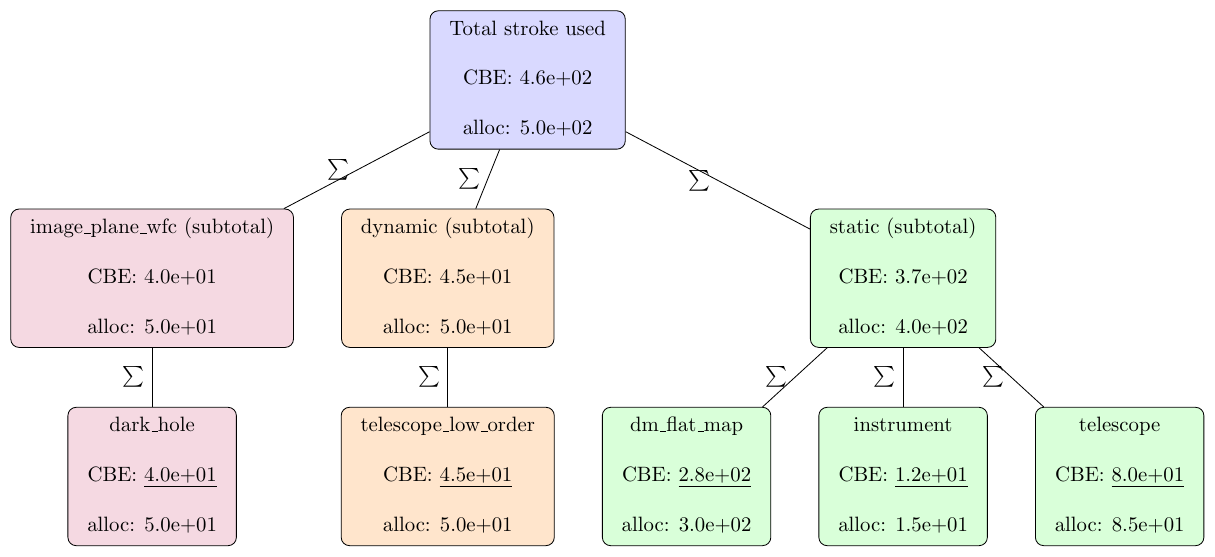

In [6]:
def tree_png(tex, dpi=150):
    """Compile standalone LaTeX to PNG and return an inline image (prints the LaTeX if tools are missing)."""
    if not (shutil.which("pdflatex") and shutil.which("pdftoppm")):
        print(tex)
        return None
    tmp = Path(tempfile.mkdtemp(prefix="budgie_png_"))
    (tmp / "tree.tex").write_text(tex, encoding="utf-8")
    subprocess.run(["pdflatex", "-interaction=nonstopmode", "tree.tex"], cwd=tmp, capture_output=True, check=True)
    subprocess.run(["pdftoppm", "-png", "-r", str(dpi), "tree.pdf", "tree"], cwd=tmp, capture_output=True, check=True)
    return Image(filename=str(sorted(tmp.glob("tree-*.png"))[0]))

tree_png(render_tikz(root))

## 5. Change the data, not the code

Two variations, each a YAML edit. First, declare the dynamic terms independent and let the
`dynamic` group RSS them (a second dynamic term is added so RSS differs from a sum):

In [7]:
variant = yaml.safe_load(BUDGET)
variant["config"]["category_combine_ops"]["dynamic"] = "rss"
variant["terms"].append({"Name": "thermal_drift", "Type": "dynamic", "Allocation": 40, "CBE": 30})
rss_root = build_tree(variant["terms"], config=variant["config"])
dynamic = next(node for node in rss_root.children if node.metadata["Type"] == "dynamic")
print(f"dynamic group: allocation {dynamic.allocation:.1f} nm (rss of 50 and 40), CBE {dynamic.value:.1f} nm")
print(summarize(rss_root, variant["budget"]["available"], "nm"))

dynamic group: allocation 64.0 nm (rss of 50 and 40), CBE 54.1 nm
Allocated:              514.0 nm
CBE:                    466.1 nm
Margin (alloc - CBE):    47.9 nm
Available:             1400.0 nm
Unallocated reserve:    886.0 nm


Second, an over-allocated budget: the DM can only deliver 450 nm, and the `dark_hole` estimate grows past its allocation.

Allocated:              500.0 nm
CBE:                    477.0 nm
Margin (alloc - CBE):    23.0 nm
Available:              450.0 nm
Unallocated reserve:    -50.0 nm


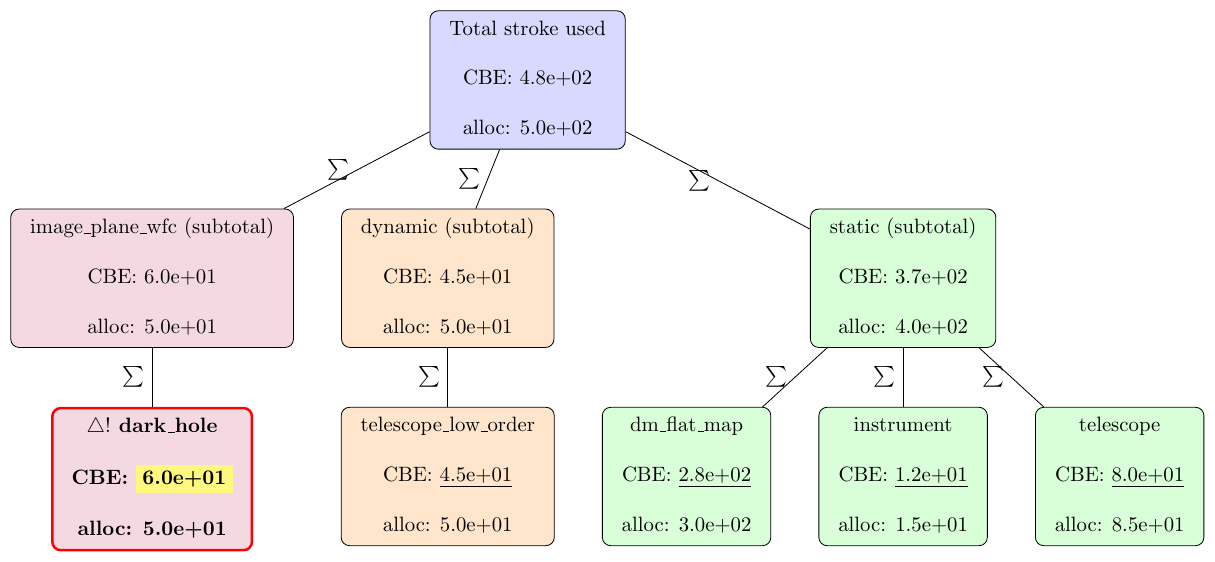

In [8]:
over = yaml.safe_load(BUDGET)
over["budget"]["available"] = 450
over["terms"][-1]["CBE"] = 60          # dark_hole CBE above its 50 nm allocation
over_root = build_tree(over["terms"], config=over["config"])
print(summarize(over_root, over["budget"]["available"], "nm"))
tree_png(render_tikz(over_root))

An unknown combine rule is rejected when the tree is built:

In [9]:
bad = yaml.safe_load(BUDGET)
bad["config"]["category_combine_ops"]["static"] = "average"
try:
    build_tree(bad["terms"], config=bad["config"])
except BudgetTreeError as err:
    print("BudgetTreeError:", err)

BudgetTreeError: Unsupported combine_op 'average'.


## 6. Reports from the command line

The same budget as a file, `dm_stroke.yaml`, is reported with the generic script in this folder's parent:

```bash
python docs/examples/report.py docs/examples/dm_stroke/dm_stroke.yaml
```

which writes `dm_stroke_report.md`, `dm_stroke_tree.txt` and `dm_stroke_tree.tex` next to the YAML.